# 01: Clean the North Indian Ocean data

Turns the raw IBTrACS file into `ni_clean.parquet`, the table every later step uses.

All the logic lives in `src/cyclone/`. This notebook only calls it in order:
load → clean → split → check → save → look at the result.
`docs/components.md` explains each module.

**Running locally:** use the `cyclone` kernel after `pip install -e .`.

**Running on Colab:** run these in a first cell:

```python
!git clone https://github.com/Anshuman-Alok-Gupta/Cyclone_Project.git
!pip install -e Cyclone_Project
```

Then choose *Runtime → Restart session*, because Python only finds a newly installed
editable package when it starts. After the restart, run this before the cells below:

```python
from google.colab import drive
drive.mount("/content/drive")

import os
os.environ["CYCLONE_DATA_DIR"] = "/content/drive/MyDrive/cyclone-project/data"
```

In [1]:
from cyclone import config
from cyclone.checks import check_expected
from cyclone.filters import clean_ni
from cyclone.io import load_ibtracs, save_parquet
from cyclone.plotting import plot_track
from cyclone.splits import assign_split

## Load

Every row and column of the raw file, with missing values and column types fixed.
Nothing has been filtered yet.

In [2]:
raw = load_ibtracs(config.ibtracs_path("NI"))
raw.shape

(62908, 174)

## Clean

The five filters from `CLAUDE.md`, in order, with the counts after each one.

In [3]:
clean = clean_ni(raw)

raw                   62,908 rows  1,861 storms
main_track            62,455 rows  1,849 storms
ni_basin              57,587 rows  1,849 storms


synoptic_hours        28,857 rows  1,807 storms
seasons                7,625 rows    449 storms
original_jtwc_fix      5,694 rows    258 storms


## Split

Each row is labelled by its storm's season: train up to 2012, val 2013–2017, test 2018–2024.

In [4]:
df = assign_split(clean)

## Check

This stops with an error if the counts differ from the ones pinned in `CLAUDE.md`.

In [5]:
check_expected(df)

Counts match: 5,694 rows, 258 storms, 184/27/47 train/val/test.


## Save

In [6]:
save_parquet(df, config.ni_clean_path())
config.ni_clean_path()

WindowsPath('D:/Cyclone_proj/data/processed/ni_clean.parquet')

## First rows

Blank (`NaN`) values in `USA_PRES` are expected: JTWC pressure is only available from
about 2001 on.

In [7]:
df.head()

,SID,NAME,SEASON,ISO_TIME,USA_LAT,USA_LON,USA_WIND,USA_PRES,split
0,1980284N09092,UNNAMED,1980,1980-10-10 06:00:00,8.8,92.3,25.0,NaN,train
1,1980284N09092,UNNAMED,1980,1980-10-10 12:00:00,8.9,92.8,25.0,NaN,train
2,1980284N09092,UNNAMED,1980,1980-10-10 18:00:00,9.1,93.2,25.0,NaN,train
3,1980284N09092,UNNAMED,1980,1980-10-11 00:00:00,9.4,93.5,20.0,NaN,train
4,1980284N09092,UNNAMED,1980,1980-10-11 06:00:00,9.6,93.3,20.0,NaN,train


## Sanity check: Cyclone Fani, 2019

Fani formed near the equator in late April, curved north through the Bay of Bengal,
and hit Odisha on 3 May 2019 as an extremely severe cyclone. The map should show that
shape, with the darkest dots just before landfall.

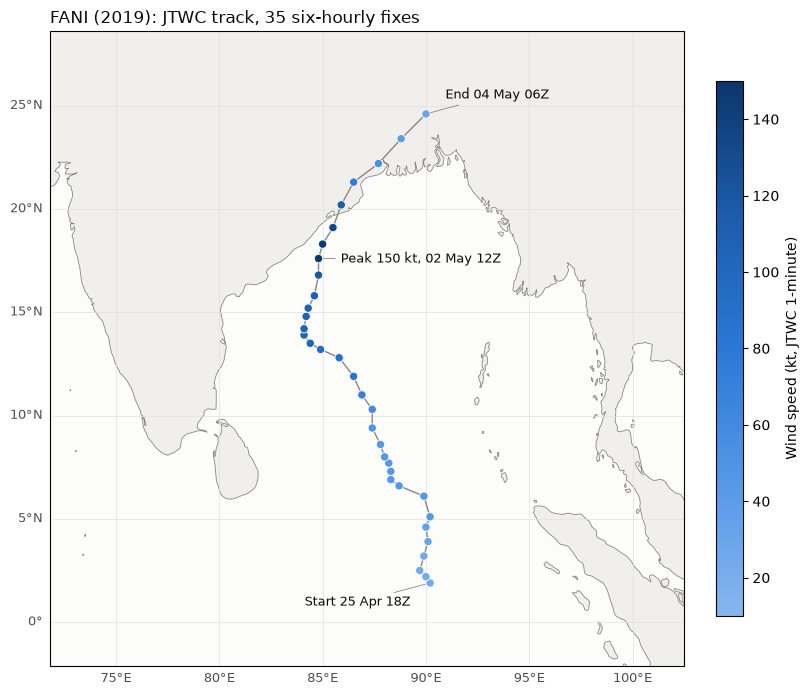

In [8]:
plot_track(df, name="FANI", season=2019);